
TASK 4

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving ai4i2020.csv to ai4i2020.csv


In [ ]:
# @title
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# @title
df = pd.read_csv("ai4i2020.csv")

print("Dataset loaded successfully!")
print("Shape of dataset:", df.shape)

Dataset loaded successfully!
Shape of dataset: (10000, 14)


In [ ]:
# @title
print("Dataset Information:\n")
df.info()
print("\nFirst 5 rows of the dataset:")
display(df.head())
print("\nColumn names:")
print(df.columns.tolist())

Dataset Information:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0



Column names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


In [ ]:
# @title
print("Numerical Features:")
print(df.select_dtypes(include=np.number).columns.tolist())

print("\nCategorical Features:")
print(df.select_dtypes(include="object").columns.tolist())

Numerical Features:


NameError: name 'df' is not defined

In [ ]:
display(df.describe())

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [ ]:
# @title
print("--- Missing Values per Column ---")
print(df.isnull().sum())

print("\n--- Total Missing Values ---")
print(df.isnull().sum().sum())

print("\n--- Total Duplicate Rows ---")
print(df.duplicated().sum())

--- Missing Values per Column ---
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

--- Total Missing Values ---
0

--- Total Duplicate Rows ---
0


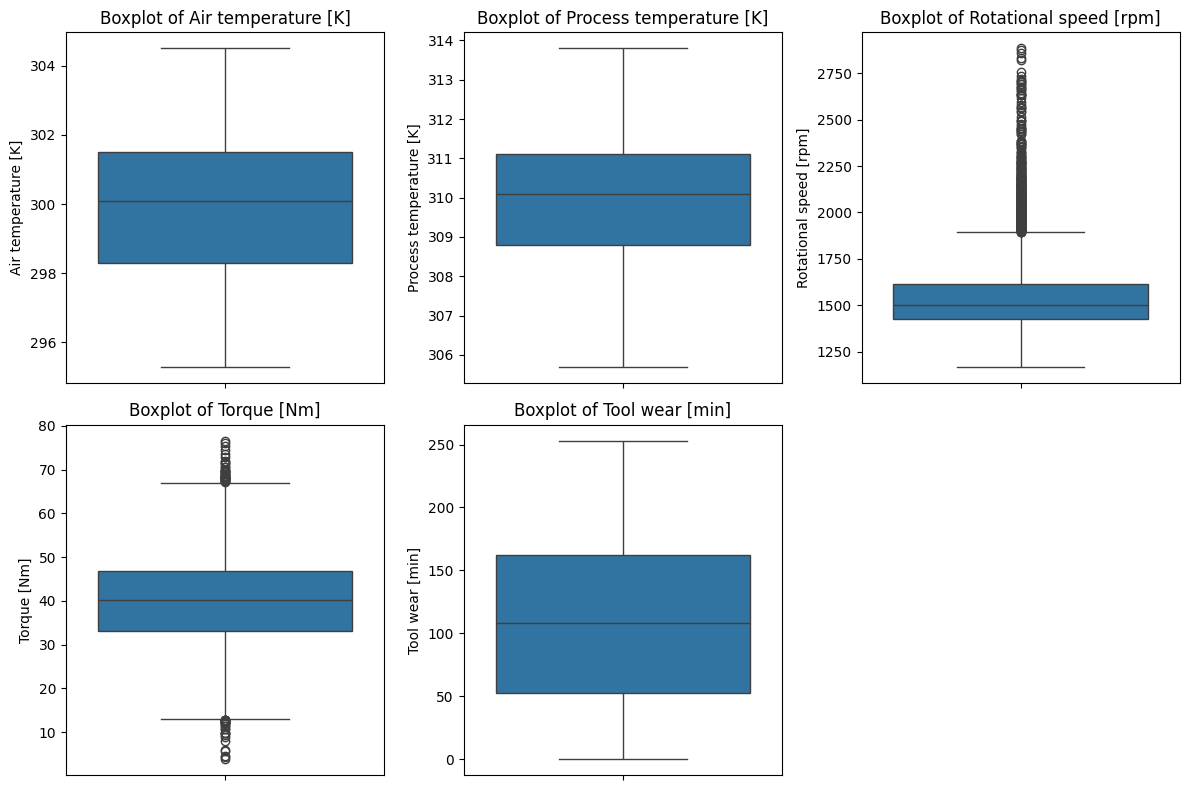

In [ ]:
# @title
cols_to_plot = ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

plt.figure(figsize=(12,8))
for i, col in enumerate(cols_to_plot, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[col])
    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

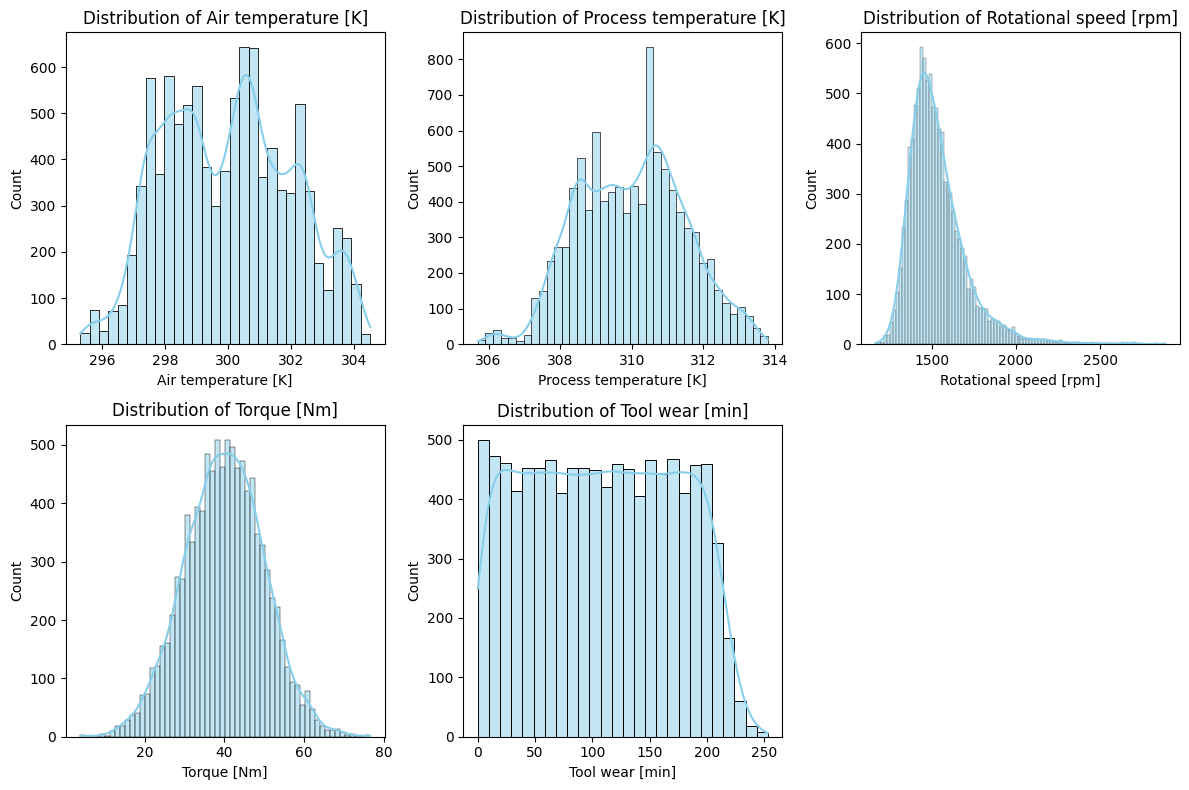

In [ ]:
# @title
plt.figure(figsize=(12, 8))
for i, col in enumerate(cols_to_plot, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df[col], kde=True, color='skyblue')
    plt.title(f'Distribution of {col}')

plt.tight_layout()
plt.show()

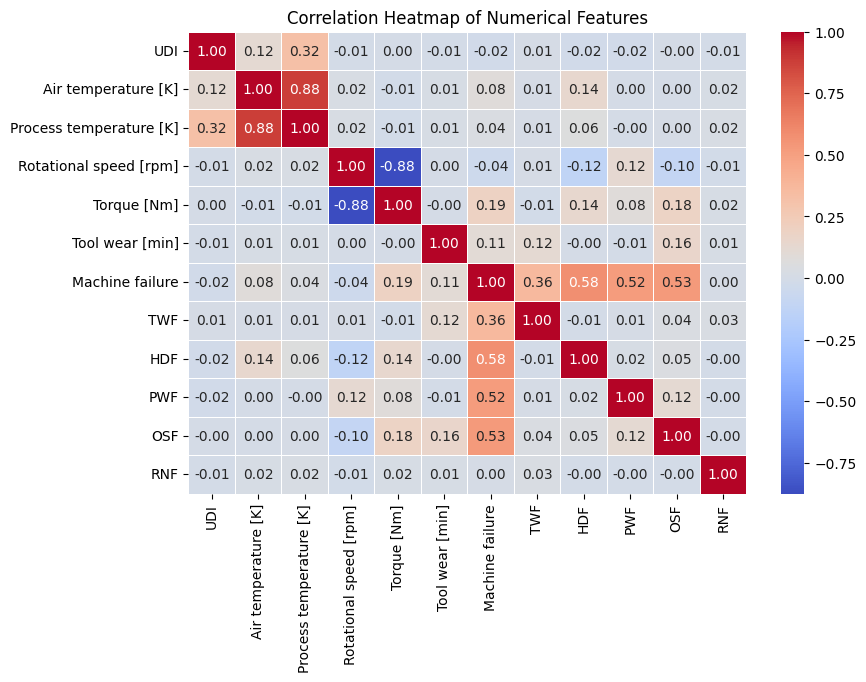

In [ ]:
# @title
plt.figure(figsize=(9, 6))
correlation_matrix = df.select_dtypes(include=[np.number]).corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

In [ ]:
# @title
from sklearn.preprocessing import StandardScaler

# 1. Create a copy for cleaning
df_cleaned = df.copy()

# 2. Drop identifier columns
df_cleaned = df_cleaned.drop(['UDI', 'Product ID'], axis=1)

# 3. Identify columns to scale (numerical features only, not the targets)
features_to_scale = ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

# 4. Perform Scaling
scaler = StandardScaler()
df_cleaned[features_to_scale] = scaler.fit_transform(df_cleaned[features_to_scale])

# 5. Save the cleaned dataset
df_cleaned.to_csv('cleaned_predictive_maintenance.csv', index=False)

print("Cleaned dataset saved as 'cleaned_predictive_maintenance.csv'")
print("\nPreview of scaled features:")
display(df_cleaned.head())

Cleaned dataset saved as 'cleaned_predictive_maintenance.csv'

Preview of scaled features:


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,M,-0.952389,-0.947360,0.068185,0.282200,-1.695984,0,0,0,0,0,0
1,L,-0.902393,-0.879959,-0.729472,0.633308,-1.648852,0,0,0,0,0,0
2,L,-0.952389,-1.014761,-0.227450,0.944290,-1.617430,0,0,0,0,0,0
3,L,-0.902393,-0.947360,-0.590021,-0.048845,-1.586009,0,0,0,0,0,0
4,L,-0.902393,-0.879959,-0.729472,0.001313,-1.554588,0,0,0,0,0,0


TASK 5

In [ ]:
# @title
# Define input features (X) and target variable (y)
# We include 'Type' and the physical measurements
X = df_cleaned[['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']]
y = df_cleaned['Machine failure']

print("Input Features (X):")
print(X.columns.tolist())
print("\nTarget Variable (y):")
print(y.name)

print("\nFirst 5 rows of input features:")
display(X.head())

Input Features (X):
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

Target Variable (y):
Machine failure

First 5 rows of input features:


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,M,-0.952389,-0.947360,0.068185,0.282200,-1.695984
1,L,-0.902393,-0.879959,-0.729472,0.633308,-1.648852
2,L,-0.952389,-1.014761,-0.227450,0.944290,-1.617430
3,L,-0.902393,-0.947360,-0.590021,-0.048845,-1.586009
4,L,-0.902393,-0.879959,-0.729472,0.001313,-1.554588


In [ ]:
# @title
from sklearn.preprocessing import LabelEncoder

# Initialize the encoder
le = LabelEncoder()

# Create a copy of X to avoid warnings and encode the 'Type' column
X_encoded = X.copy()
X_encoded['Type'] = le.fit_transform(X['Type'])

print("Mapping of categories:")
for index, label in enumerate(le.classes_):
    print(f"{label} -> {index}")

print("\nUpdated Input Features (X) with encoded Type:")
display(X_encoded.head())

Mapping of categories:
H -> 0
L -> 1
M -> 2

Updated Input Features (X) with encoded Type:


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,2,-0.952389,-0.947360,0.068185,0.282200,-1.695984
1,1,-0.902393,-0.879959,-0.729472,0.633308,-1.648852
2,1,-0.952389,-1.014761,-0.227450,0.944290,-1.617430
3,1,-0.902393,-0.947360,-0.590021,-0.048845,-1.586009
4,1,-0.902393,-0.879959,-0.729472,0.001313,-1.554588


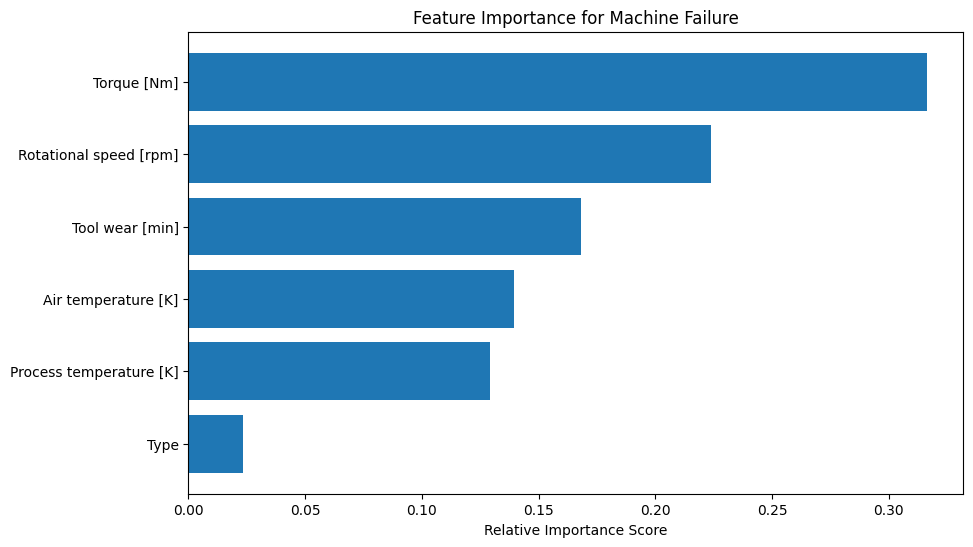

In [ ]:
# @title
from sklearn.ensemble import RandomForestClassifier

# Initialize and fit a Random Forest model
rf = RandomForestClassifier(random_state=42)
rf.fit(X_encoded, y)

# Get feature importance scores
importances = rf.feature_importances_
feature_names = X_encoded.columns

# Sort and plot
indices = np.argsort(importances)
plt.figure(figsize=(10, 6))
plt.title("Feature Importance for Machine Failure")
plt.barh(range(len(indices)), importances[indices], align='center')
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel("Relative Importance Score")
plt.show()

In [ ]:
# @title
from sklearn.model_selection import train_test_split

# Split the data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

print("Data split successfully!")
print(f"X_train shape: {X_train.shape} (80% features)")
print(f"X_test shape: {X_test.shape} (20% features)")
print(f"y_train shape: {y_train.shape} (80% target)")
print(f"y_test shape: {y_test.shape} (20% target)")

Data split successfully!
X_train shape: (8000, 6) (80% features)
X_test shape: (2000, 6) (20% features)
y_train shape: (8000,) (80% target)
y_test shape: (2000,) (20% target)


--- Logistic Regression Results ---
Accuracy Score: 0.9735

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1939
           1       0.67      0.26      0.38        61

    accuracy                           0.97      2000
   macro avg       0.82      0.63      0.68      2000
weighted avg       0.97      0.97      0.97      2000



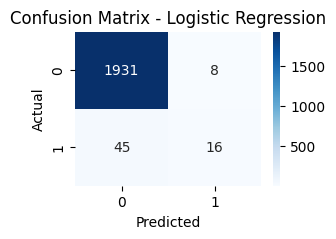

In [ ]:
# @title
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Initialize the model
log_model = LogisticRegression(random_state=42)

# 2. Train the model
log_model.fit(X_train, y_train)

# 3. Make predictions on the test set
y_pred_log = log_model.predict(X_test)

# 4. Evaluate the model
print("--- Logistic Regression Results ---")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred_log):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_log))

# 5. Confusion Matrix
plt.figure(figsize=(3,2))
sns.heatmap(confusion_matrix(y_test, y_pred_log), annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

--- Decision Tree Results ---
Accuracy Score: 0.9790

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1939
           1       0.77      0.44      0.56        61

    accuracy                           0.98      2000
   macro avg       0.88      0.72      0.78      2000
weighted avg       0.98      0.98      0.98      2000



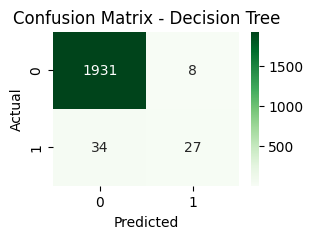

In [ ]:
# @title
from sklearn.tree import DecisionTreeClassifier

# 1. Initialize the Decision Tree
dt_model = DecisionTreeClassifier(random_state=42, max_depth=5)

# 2. Train the model
dt_model.fit(X_train, y_train)

# 3. Make predictions
y_pred_dt = dt_model.predict(X_test)

# 4. Evaluate
print("--- Decision Tree Results ---")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred_dt):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

# 5. Plot Confusion Matrix
plt.figure(figsize=(3,2))
sns.heatmap(confusion_matrix(y_test, y_pred_dt), annot=True, fmt='d', cmap='Greens')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Decision Tree')
plt.show()

--- Random Forest Results ---
Accuracy Score: 0.9840

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1939
           1       0.84      0.59      0.69        61

    accuracy                           0.98      2000
   macro avg       0.91      0.79      0.84      2000
weighted avg       0.98      0.98      0.98      2000



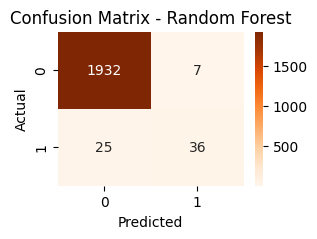

In [ ]:
# @title
from sklearn.ensemble import RandomForestClassifier

# 1. Initialize the Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# 2. Train the model
rf_model.fit(X_train, y_train)

# 3. Make predictions
y_pred_rf = rf_model.predict(X_test)

# 4. Evaluate
print("--- Random Forest Results ---")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred_rf):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

# 5. Plot Confusion Matrix
plt.figure(figsize=(3,2))
sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', cmap='Oranges')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Random Forest')
plt.show()

--- SVM Results ---
Accuracy Score: 0.9760

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1939
           1       0.81      0.28      0.41        61

    accuracy                           0.98      2000
   macro avg       0.89      0.64      0.70      2000
weighted avg       0.97      0.98      0.97      2000



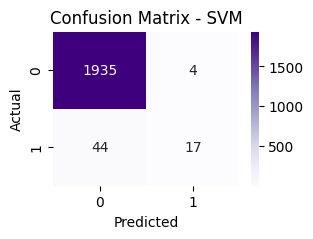

In [ ]:
# @title
from sklearn.svm import SVC

# 1. Initialize the SVM model
svm_model = SVC(kernel='rbf', random_state=42)

# 2. Train the model
svm_model.fit(X_train, y_train)

# 3. Make predictions
y_pred_svm = svm_model.predict(X_test)

# 4. Evaluate
print("--- SVM Results ---")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred_svm):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

# 5. Plot Confusion Matrix
plt.figure(figsize=(3,2))
sns.heatmap(confusion_matrix(y_test, y_pred_svm), annot=True, fmt='d', cmap='Purples')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - SVM')
plt.show()

In [ ]:
# @title
import pandas as pd

# Gather the accuracy scores
results = {
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest', 'SVM'],
    'Accuracy Score': [
        accuracy_score(y_test, y_pred_log),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_svm)
    ]
}

# Create a DataFrame for display
comparison_df = pd.DataFrame(results)
comparison_df = comparison_df.sort_values(by='Accuracy Score', ascending=False)

print("--- Supervised Learning Model Comparison ---")
display(comparison_df)

--- Supervised Learning Model Comparison ---


,Model,Accuracy Score
2,Random Forest,0.9840
1,Decision Tree,0.9790
3,SVM,0.9760
0,Logistic Regression,0.9735


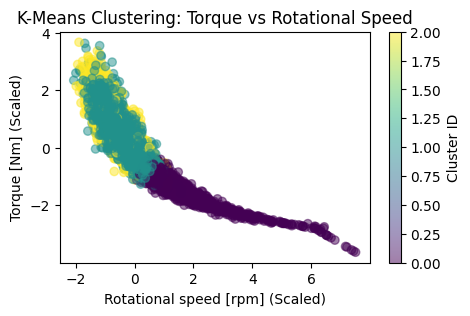

Unsupervised clustering complete!


In [ ]:
# @title
from sklearn.cluster import KMeans

# 1. Initialize KMeans - we will look for 3 clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

# 2. Fit the model using our scaled features
# Note: We use the same features but ignore the 'Machine failure' label
clusters = kmeans.fit_predict(X_encoded)

# 3. Visualize the clusters
plt.figure(figsize=(5, 3))
plt.scatter(X_encoded['Rotational speed [rpm]'], X_encoded['Torque [Nm]'], c=clusters, cmap='viridis', alpha=0.5)
plt.title('K-Means Clustering: Torque vs Rotational Speed')
plt.xlabel('Rotational speed [rpm] (Scaled)')
plt.ylabel('Torque [Nm] (Scaled)')
plt.colorbar(label='Cluster ID')
plt.show()

print("Unsupervised clustering complete!")

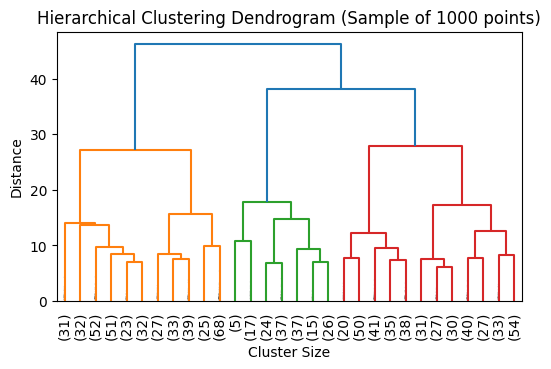

Hierarchical clustering visualization complete!


In [ ]:
# @title
from scipy.cluster.hierarchy import dendrogram, linkage

# 1. Perform Hierarchical Clustering using Ward's method
# We take a sample of 1000 points just for the dendrogram visualization so it remains readable
X_sample = X_encoded.sample(1000, random_state=42)
Z = linkage(X_sample, method='ward')

# 2. Plot the Dendrogram
plt.figure(figsize=(6, 3.5))
plt.title("Hierarchical Clustering Dendrogram (Sample of 1000 points)")
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90, leaf_font_size=10, show_contracted=True)
plt.xlabel("Cluster Size")
plt.ylabel("Distance")
plt.show()

print("Hierarchical clustering visualization complete!")

--- Linear Regression Results (Predicting Tool Wear) ---
Mean Squared Error: 1.0554
R2 Score: -0.0015


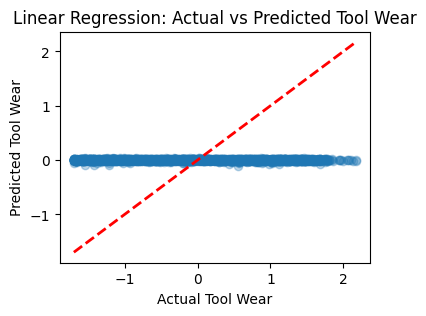

In [ ]:
# @title
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Define features and new target (Tool wear)
# We remove 'Tool wear' from our X and set it as y
X_reg = X_encoded.drop('Tool wear [min]', axis=1)
y_reg = X_encoded['Tool wear [min]']

# 2. Split data
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

# 3. Train Linear Regression
lin_reg = LinearRegression()
lin_reg.fit(X_train_reg, y_train_reg)

# 4. Predict
y_pred_reg = lin_reg.predict(X_test_reg)

# 5. Evaluate
print("--- Linear Regression Results (Predicting Tool Wear) ---")
print(f"Mean Squared Error: {mean_squared_error(y_test_reg, y_pred_reg):.4f}")
print(f"R2 Score: {r2_score(y_test_reg, y_pred_reg):.4f}")

# 6. Plot Predicted vs Actual
plt.figure(figsize=(4, 3))
plt.scatter(y_test_reg, y_pred_reg, alpha=0.3)
plt.plot([y_test_reg.min(), y_test_reg.max()], [y_test_reg.min(), y_test_reg.max()], 'r--', lw=2)
plt.xlabel('Actual Tool Wear')
plt.ylabel('Predicted Tool Wear')
plt.title('Linear Regression: Actual vs Predicted Tool Wear')
plt.show()